### 2.1 Score Collection

The symbolic scores used in this project were collected primarily from two online sources:

- [MuseScore](https://musescore.com/)
- [Kunst der Fuge](https://kunstderfuge.com/)

Both websites are mentioned in Jiang's dissertation (2020, Section 5.1) as examples of online resources providing symbolic score data.

The collected scores are available in **MusicXML (MXL)** and **MIDI** formats. These files serve as the input to the score-processing pipeline, where musical notes and their score positions are extracted and subsequently organized into sequences of score states.

### 2.2a Initial Score Inspection and Diagnostics

Before extracting note-level information, we inspected the collected symbolic scores to verify that they could be loaded using **Partitura**, and examine their structure, particularly the number of available instrumental parts.

During this inspection, two problematic MusicXML files were identified and subsequently replaced with valid alternatives.

The following table provides an overview of the final score collection, including each file's format and the number of parts identified by Partitura.

In [1]:
from pathlib import Path
import warnings

import pandas as pd
import partitura as pt

# Locate the score directory (notebook in PW/ or PW/score-processing/)
score_dir = Path("score")
if not score_dir.is_dir():
    score_dir = Path("../score")

score_extensions = {".mxl", ".xml", ".musicxml", ".mid", ".midi"}


def count_parts(score):
    """Count parts returned by Partitura."""
    if hasattr(score, "parts"):
        return len(score.parts)
    if hasattr(score, "notes_tied"):
        return 1
    if isinstance(score, (list, tuple)):
        return sum(count_parts(item) for item in score)
    raise TypeError(f"Unexpected score type: {type(score)}")


records = []

for path in sorted(score_dir.iterdir()):
    if path.suffix.lower() not in score_extensions:
        continue

    is_midi = path.suffix.lower() in {".mid", ".midi"}

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        if is_midi:
            score = pt.load_score_midi(str(path), quantization_unit=1)
        else:
            score = pt.load_score(str(path))

    records.append({
        "Score file": path.name,
        "Format": "MIDI" if is_midi else "MusicXML",
        "Available parts": count_parts(score),
    })

score_inventory = pd.DataFrame(records)

print(f"Total scores: {len(score_inventory)}")
display(score_inventory)

Total scores: 16


,Score file,Format,Available parts
0,1st-movement-piano-concerto-op54-robert-schuma...,MusicXML,13
1,24-preludes-op28-n4-frederic-chopin.mxl,MusicXML,1
2,"Schubert — Ständchen, D. 957 No. 4.mxl",MusicXML,1
3,barcarolle-opus-60-in-f-major.mxl,MusicXML,1
4,chopin-ballade-no-1-in-g-minor-op-23.mxl,MusicXML,2
5,debussy-fille-aux-cheveux-de-lin.mxl,MusicXML,1
6,debussy-voiles.mxl,MusicXML,1
7,etude-s-1413-in-g-minor-la-campanella-liszt.mxl,MusicXML,1
8,moment-musicaux-op-94-no-2-in-a-flat-major-fra...,MusicXML,1
9,mozart_piano_concerto_17_453_1_(nc)fisher.mid,MIDI,4


### 2.2b Piano Part Identification and Selection

Before extracting the notes, we identified which parts of each symbolic score corresponded to the piano. This was particularly important for multi-instrument scores, such as piano concertos, where extracting every part would introduce notes from the orchestral accompaniment.

We followed these principles:

1. **Select piano parts only.** Non-piano instrumental parts were excluded.

2. **Accept unambiguous single-part piano scores.** Scores containing only one clearly identified piano part required no further selection.

3. **Inspect multi-part scores individually.** Instrument names, MIDI program information, pitch ranges, and note distributions were examined to identify the relevant piano parts.

4. **Preserve all relevant piano parts.** Multiple parts were retained when they represented the piano performance, including sparse parts containing relatively few notes.

5. **Record selections explicitly.** The selected part indices were stored in `score_part_selection.json` to ensure consistent and reproducible extraction.

In [2]:

import json
from pathlib import Path

# Locate the part-selection configuration
config_path = Path("score-processing/score_part_selection.json")
if not config_path.exists():
    config_path = Path("score_part_selection.json")

with config_path.open("r", encoding="utf-8") as f:
    part_selection = json.load(f)

# Focus on scores with multiple available parts
multi_part_scores = score_inventory[
    score_inventory["Available parts"] > 1
]

records = []

for _, score in multi_part_scores.iterrows():
    filename = score["Score file"]
    selection = part_selection[filename]

    records.append({
        "Score": Path(filename).stem,
        "Available parts": score["Available parts"],
        "Selected parts": ", ".join(
            f"P{part}" for part in selection["parts"]
        ),
        "Selection reason": selection.get("reason", ""),
    })

selection_table = pd.DataFrame(records)

display(selection_table)

,Score,Available parts,Selected parts,Selection reason
0,1st-movement-piano-concerto-op54-robert-schumann,13,P8,P8 is the piano part; orchestral parts excluded
1,chopin-ballade-no-1-in-g-minor-op-23,2,"P1, P2","Retain both parts of this solo-piano score, in..."
2,mozart_piano_concerto_17_453_1_(nc)fisher,4,"P1, P2",Raw MIDI tracks 1+2 have piano programs and la...
3,sonata_24_1_(c)iscenko,3,"P1, P2, P3",Retain all sounding parts of solo-keyboard sco...
4,sonata_24_2_(c)iscenko,3,"P1, P2, P3",Retain all sounding parts of solo-keyboard sco...
5,sonata_24_3_(c)iscenko,3,"P1, P2, P3",Retain all sounding parts of solo-keyboard sco...


### 2.2c Note-Level Extraction

After identifying the relevant piano parts, we used **Partitura** to extract individual note information from the collected MusicXML and MIDI scores.

For each note, we recorded its **MIDI pitch, onset and offset positions, and duration**, along with additional metadata such as part identifiers, measure information, and grace-note or tie-related properties.

The extracted notes were organized chronologically and saved in **CSV and NPZ formats** for subsequent processing. All original note timings were preserved at this stage.

In [3]:
import warnings

# Load a representative piano score
score_path = score_dir / "24-preludes-op28-n4-frederic-chopin.mxl"

# Suppress known Partitura parser warnings for this demonstration
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    score = pt.load_score(str(score_path))

# Access the piano part
piano_part = score.parts[0]

# Convert internal score divisions to quarter-note units
quarter_map = piano_part.quarter_map

# Retrieve notes, including tied-note groups
notes = sorted(
    piano_part.notes_tied,
    key=lambda note: (note.start.t, note.midi_pitch)
)

records = []

for note in notes[:10]:
    end_point = (
        note.end_tied
        if note.end_tied is not None
        else note.end
    )

    onset = float(quarter_map(note.start.t))
    offset = float(quarter_map(end_point.t))

    records.append({
        "MIDI pitch": int(note.midi_pitch),
        "Onset (quarter notes)": onset,
        "Offset (quarter notes)": offset,
        "Duration (quarter notes)": offset - onset,
        "Grace note": isinstance(note, pt.score.GraceNote),
    })

note_example = pd.DataFrame(records)

display(note_example.round(4))

,MIDI pitch,Onset (quarter notes),Offset (quarter notes),Duration (quarter notes),Grace note
0,59,0.00,0.75,0.75,False
1,71,0.75,1.00,0.25,False
2,55,1.00,1.50,0.50,False
3,59,1.00,1.50,0.50,False
4,64,1.00,1.50,0.50,False
5,71,1.00,4.00,3.00,False
6,55,1.50,2.00,0.50,False
7,59,1.50,2.00,0.50,False
8,64,1.50,2.00,0.50,False
9,55,2.00,2.50,0.50,False


### Note Extraction Rules

To ensure consistent extraction across MusicXML and MIDI scores, we followed these rules:

1. **Ordinary notes:** Each note is represented by its MIDI pitch, onset, offset, and duration. Notes must have valid pitches and positive durations.

2. **Tied notes:** Notes connected by ties are treated as a single note event, extending from the first note's onset to the final tied note's offset. The number of tied segments is also recorded.

3. **Grace notes:** All grace notes are preserved and explicitly identified. Their original onset and offset positions are retained, including cases where Partitura assigns them nonzero durations. Their treatment during score-state construction is considered separately.

4. **Musical timing:** Note positions are converted from Partitura's internal divisions into quarter-note units using `quarter_map`. They are also stored as fractions of a whole note to preserve precise musical positions. No additional timing corrections are applied during extraction.

5. **Note metadata:** Available information such as part identifiers, note IDs, measure numbers, staff, and voice is retained. Fields unavailable in the source format are left unspecified rather than inferred.

Finally, the extracted notes are sorted chronologically by onset position and exported in **CSV and NPZ formats**. These note-level records form the input for subsequent score-state construction.

In [4]:

# Load the note-extraction summary
summary_path = Path("score-processing/score-notes/extraction_summary.csv")
if not summary_path.exists():
    summary_path = Path("score-notes/extraction_summary.csv")

extraction_summary = pd.read_csv(summary_path)

# Consider only the original score versions
original = extraction_summary[
    extraction_summary["variant"] == "original"
].copy()

# Identify score formats
original["Format"] = original["source_file"].apply(
    lambda name: "MIDI" if Path(name).suffix.lower() in {".mid", ".midi"}
    else "MusicXML"
)

# Summarize extraction results by format
summary = original.groupby("Format").agg(
    Scores=("source_file", "count"),
    Notes=("notes", "sum"),
    Grace_notes=("grace_notes", "sum"),
    Tied_groups=("tied_groups", "sum")
)

summary.loc["Total"] = summary.sum()

display(summary)

,Scores,Notes,Grace_notes,Tied_groups
Format,,,,
MIDI,4,10642,0,43
MusicXML,12,36387,293,942
Total,16,47029,293,985


### 2.2e Experimental MIDI Timing Adjustment

During the initial inspection of the MIDI scores, we noticed that many note onsets aligned closely with expected rhythmic positions, while note offsets were considerably less consistent. Further examination revealed that numerous notes ended slightly before nearby musical boundaries.

Although such differences may reflect intentional articulation, they can also arise from MIDI encoding or export conventions. In our score representation, even a very short gap between notes can introduce an additional musical event, potentially complicating the subsequent score-state construction.

To investigate this issue, we developed alternative versions of the four MIDI scores with conservatively adjusted note offsets, while preserving the original versions for comparison.

Uniquely matched corrected notes: 1396
Isolated releases: 408
Existing boundaries: 988
Original note timings found in raw MIDI: 1396


,part_index,pitch_midi,offset_quarter_original,offset_quarter_adjusted,extension_ticks,case_type,raw_midi_match
0,3,58,15.9271,16.0,7,isolated_release,True
1,3,39,33.9271,34.0,7,isolated_release,True
2,3,46,34.9271,35.0,7,isolated_release,True


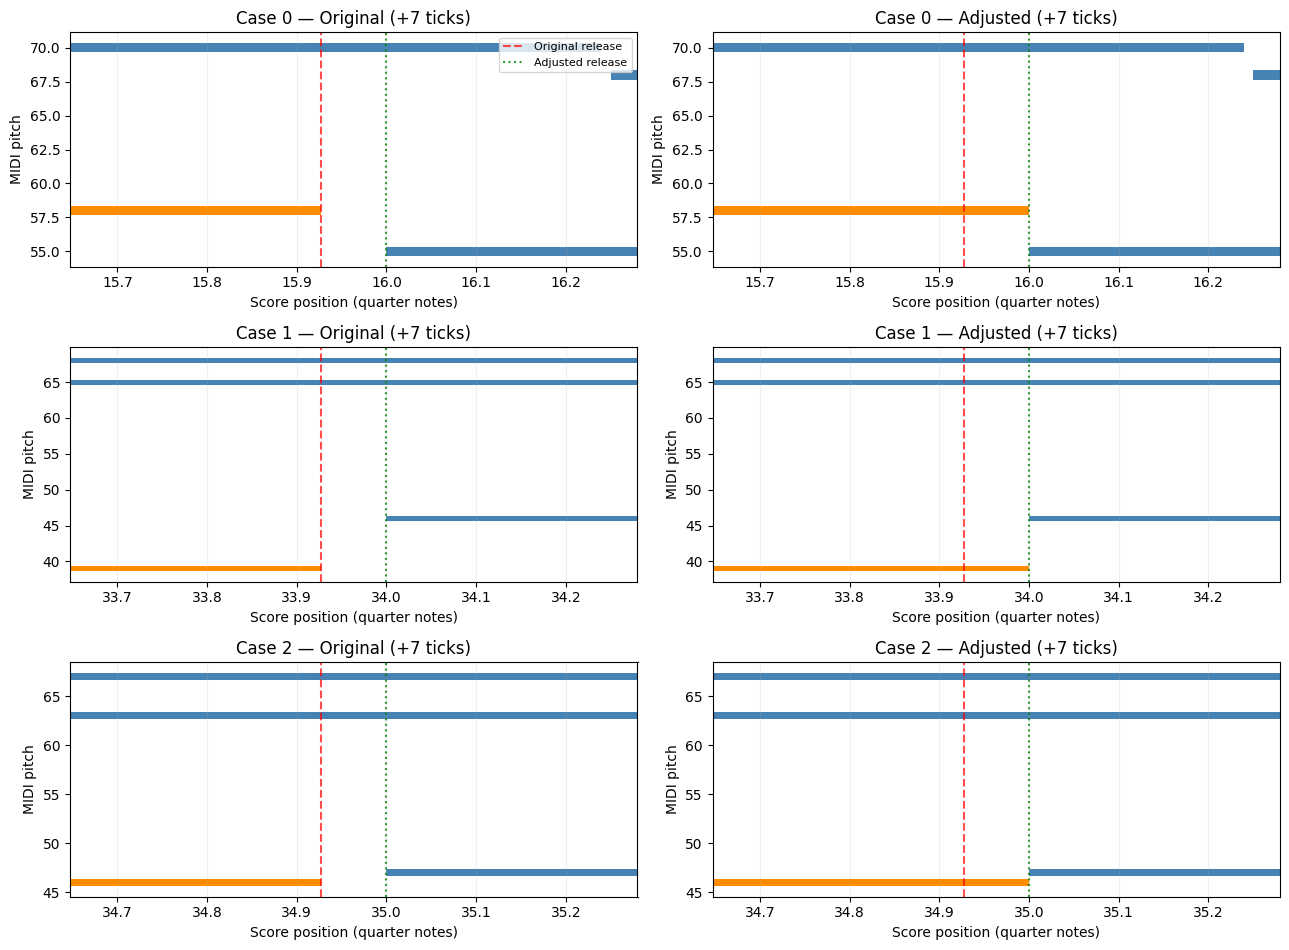

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import mido
from collections import Counter, defaultdict, deque

# Locate the extracted note records
notes_dir = Path("score-processing/score-notes")
if not notes_dir.exists():
    notes_dir = Path("score-notes")

score_name = "sonata_24_2_(c)iscenko.mid"
adjusted_dir = notes_dir / "timing-adjusted"

# Find the original and adjusted note files
original_summary = pd.read_csv(notes_dir / "extraction_summary.csv")
timing_summary = pd.read_csv(
    adjusted_dir / "timing_correction_summary.csv"
)

original_info = original_summary[
    original_summary["source_file"] == score_name
].iloc[0]

adjusted_info = timing_summary[
    timing_summary["source_file"] == score_name
].iloc[0]

original = pd.read_csv(
    notes_dir / Path(original_info["csv"]).name
)
adjusted = pd.read_csv(
    adjusted_dir / Path(adjusted_info["csv"]).name
)

# Match notes by part, pitch, and onset.
# Exclude ambiguous matches with identical identifying fields.
keys = ["part_index", "pitch_midi", "onset_whole_fraction"]

original_unique = original[
    ~original.duplicated(keys, keep=False)
]
adjusted_unique = adjusted[
    ~adjusted.duplicated(keys, keep=False)
]

matched = original_unique[
    keys + ["onset_quarter", "offset_quarter"]
].merge(
    adjusted_unique[keys + ["offset_quarter"]],
    on=keys,
    suffixes=("_original", "_adjusted"),
    validate="one_to_one"
)

# Find notes whose offsets were extended
changed = matched[
    matched["offset_quarter_adjusted"]
    > matched["offset_quarter_original"] + 1e-8
].copy()

changed["extension_ticks"] = (
    changed["offset_quarter_adjusted"]
    - changed["offset_quarter_original"]
) * 96  # 96 ticks per quarter note in this MIDI file

# --- Inspection settings ---
case_type = "isolated_release"
# Options: "isolated_release", "existing_boundary", "all"

first_case = 0
number_of_cases = 3

# Read the actual MIDI resolution
raw_midi = mido.MidiFile(str(score_dir / score_name))
ticks_per_quarter = raw_midi.ticks_per_beat

# Express original and adjusted offsets in MIDI ticks
changed["release_tick"] = np.rint(
    changed["offset_quarter_original"] * ticks_per_quarter
).astype(int)

changed["target_tick"] = np.rint(
    changed["offset_quarter_adjusted"] * ticks_per_quarter
).astype(int)

changed["extension_ticks"] = (
    changed["target_tick"] - changed["release_tick"]
)

# Check whether other note events already occur
# at the original release position.
# We consider all selected piano parts.
onset_ticks = set(
    np.rint(original["onset_quarter"] * ticks_per_quarter).astype(int)
)

offset_counts = Counter(
    np.rint(original["offset_quarter"] * ticks_per_quarter).astype(int)
)

changed["onset_at_release"] = changed["release_tick"].isin(onset_ticks)

changed["other_offset_at_release"] = changed["release_tick"].map(
    lambda tick: offset_counts[tick] > 1
)

changed["case_type"] = np.where(
    changed["onset_at_release"] | changed["other_offset_at_release"],
    "existing_boundary",
    "isolated_release"
)

# Cross-check against original raw MIDI note-on/note-off pairs
raw_note_pairs = set()

for track in raw_midi.tracks:
    tick = 0
    active = defaultdict(deque)

    for msg in track:
        tick += msg.time

        if msg.type == "note_on" and msg.velocity > 0:
            active[(msg.channel, msg.note)].append(tick)

        elif msg.type == "note_off" or (
            msg.type == "note_on" and msg.velocity == 0
        ):
            key = (msg.channel, msg.note)

            if active[key]:
                raw_note_pairs.add((
                    msg.note,
                    active[key].popleft(),
                    tick
                ))

changed["raw_midi_match"] = changed.apply(
    lambda row: (
        int(row["pitch_midi"]),
        round(row["onset_quarter"] * ticks_per_quarter),
        int(row["release_tick"])
    ) in raw_note_pairs,
    axis=1
)

# Summarize the categories
print(f"Uniquely matched corrected notes: {len(changed)}")
print(f"Isolated releases: {(changed['case_type'] == 'isolated_release').sum()}")
print(f"Existing boundaries: {(changed['case_type'] == 'existing_boundary').sum()}")
print(f"Original note timings found in raw MIDI: {changed['raw_midi_match'].sum()}")

# Select examples
cases = (
    changed if case_type == "all"
    else changed[changed["case_type"] == case_type]
)

cases = cases.sort_values(
    ["extension_ticks", "offset_quarter_original"],
    ascending=[False, True]
).reset_index(drop=True)

selected = cases.iloc[first_case:first_case + number_of_cases]

if selected.empty:
    raise ValueError("No cases found. Change case_type or first_case.")

display(
    selected[[
        "part_index", "pitch_midi",
        "offset_quarter_original",
        "offset_quarter_adjusted",
        "extension_ticks", "case_type", "raw_midi_match"
    ]].round(4)
)

# Plot original and adjusted versions side by side
fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(13, 3.2 * len(selected)),
    squeeze=False
)

for i, (_, case) in enumerate(selected.iterrows()):

    old_end = case["offset_quarter_original"]
    new_end = case["offset_quarter_adjusted"]

    left = old_end - 0.28
    right = new_end + 0.28

    for j, (label, data) in enumerate([
        ("Original", original),
        ("Adjusted", adjusted)
    ]):
        ax = axes[i, j]

        # Include all piano parts to show surrounding note events
        passage = data[
            (data["onset_quarter"] < right)
            & (data["offset_quarter"] > left)
        ]

        for _, note in passage.iterrows():

            start = max(note["onset_quarter"], left)
            end = min(note["offset_quarter"], right)

            highlighted = (
                note["part_index"] == case["part_index"]
                and note["pitch_midi"] == case["pitch_midi"]
                and abs(
                    note["onset_quarter"] - case["onset_quarter"]
                ) < 1e-8
            )

            ax.broken_barh(
                [(start, end - start)],
                (note["pitch_midi"] - 0.35, 0.7),
                facecolors=(
                    "darkorange" if highlighted else "steelblue"
                )
            )

        ax.axvline(
            old_end, color="red", linestyle="--",
            alpha=0.7, label="Original release"
        )

        ax.axvline(
            new_end, color="green", linestyle=":",
            alpha=0.8, label="Adjusted release"
        )

        ax.set_xlim(left, right)
        ax.set_title(
            f"Case {first_case + i} — {label} "
            f"(+{int(case['extension_ticks'])} ticks)"
        )
        ax.set_ylabel("MIDI pitch")
        ax.set_xlabel("Score position (quarter notes)")
        ax.grid(axis="x", alpha=0.2)

axes[0, 0].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


### MIDI Timing Correction Strategy

To address the short note-ending gaps identified during inspection, we created alternative versions of the four MIDI scores by selectively extending note offsets. The correction rules differed according to the timing characteristics of the files:

1. **Mozart Piano Concerto No. 17:** Notes exhibiting a systematic four-tick shortening pattern were selectively extended by **4 MIDI ticks**.

2. **Three sonata MIDI files:** Notes ending shortly before an existing rhythmic onset boundary were extended to that boundary, with a maximum adjustment of **8 MIDI ticks**. Since these files use 96 ticks per quarter note, the maximum adjustment is smaller than a thirty-second note.

Only note offsets were adjusted; note pitches and onset positions remained unchanged. The algorithm also checked for potentially problematic corrections, such as extending notes across other note events or creating overlaps with subsequent notes of the same pitch.

The original MIDI files and extracted note records were left unchanged. Adjusted versions were saved separately, with records of the applied corrections, allowing both representations to be compared during model evaluation.

In [6]:
# Load the MIDI timing correction summary
summary_path = notes_dir / "timing-adjusted" / "timing_correction_summary.csv"

timing_summary = pd.read_csv(summary_path)

# Show the main transformation statistics
correction_table = timing_summary[[
    "source_file",
    "corrected_raw_note_offs",
    "max_applied_extension_ticks"
]].copy()

correction_table.columns = [
    "Score",
    "Corrected note offsets",
    "Maximum extension (ticks)"
]

correction_table["Score"] = (
    correction_table["Score"]
    .str.replace(".mid", "", regex=False)
)

display(correction_table)

print(
    f"Total corrected note offsets: "
    f"{correction_table['Corrected note offsets'].sum():,}"
)


,Score,Corrected note offsets,Maximum extension (ticks)
0,mozart_piano_concerto_17_453_1_(nc)fisher,3169,4
1,sonata_24_1_(c)iscenko,1776,7
2,sonata_24_2_(c)iscenko,1396,8
3,sonata_24_3_(c)iscenko,846,7


Total corrected note offsets: 7,187


### 2.2d Note Extraction Validation

After extracting the notes, we used `validate_score_notes.py` to verify the consistency and correctness of the resulting data. The validation included the following checks:

- **Note validity:** MIDI numbers were within the valid range (0–127), ordinary notes had positive durations, and grace notes had nonnegative durations.
- **Extraction consistency:** Extracted note counts and timing information were compared against Partitura's interpretation of the original scores.
- **Export consistency:** The CSV and NPZ files were checked to ensure they contained equivalent note information.
- **MIDI-specific checks:** Raw MIDI note-on and note-off events were compared with the extracted note records to identify possible discrepancies.

These checks establish the **technical consistency** of the extracted data, but do not guarantee complete correspondence with the intended musical notation.

In [7]:
# Load the note validation summary
validation_path = Path("score-processing/note_validation_summary.csv")

if not validation_path.exists():
    validation_path = Path("note_validation_summary.csv")

validation = pd.read_csv(validation_path)

# Summarize validation results
validation_results = (
    validation["status"]
    .value_counts()
    .reindex(["PASS", "REVIEW", "FAIL"], fill_value=0)
    .rename_axis("Validation status")
    .reset_index(name="Number of scores")
)

display(validation_results)

print(f"Total scores validated: {len(validation)}")

,Validation status,Number of scores
0,PASS,10
1,REVIEW,6
2,FAIL,0


Total scores validated: 16


### 2.3. Score-State Construction

Following Jiang's event-based score representation, the extracted notes were converted into an ordered sequence of **score states (musical events)**.

A new state begins whenever a note starts or ends. Each state represents the **set of active MIDI pitches** over the interval until the next event boundary. Its **nominal musical length** is the distance between these boundaries, expressed in musical units rather than seconds.

Simultaneous note events share a single boundary, while intervals with no active notes are represented as **rests (empty pitch sets)**. Repeated notes may introduce new states even when the active pitch set remains unchanged.

Grace notes were excluded from state construction but preserved in the original note records. The same construction procedure was applied to both original and timing-adjusted MIDI representations.

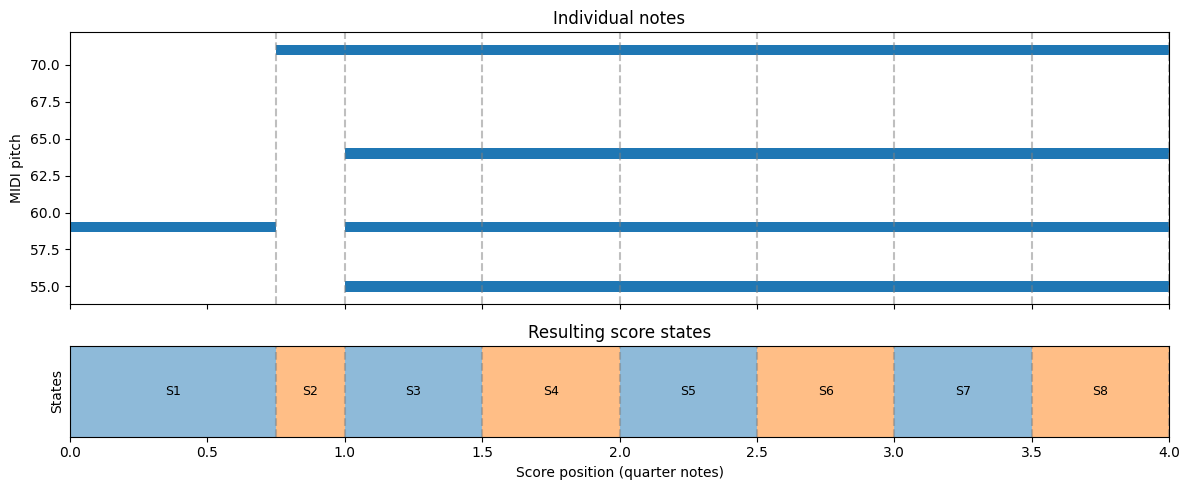

In [8]:
score_name = "24-preludes-op28-n4-frederic-chopin.mxl"

# Locate the original note and score-state files
notes_dir = Path("score-processing/score-notes")
states_dir = Path("score-processing/score-states")

if not notes_dir.exists():
    notes_dir = Path("score-notes")
    states_dir = Path("score-states")

# Read the corresponding CSV filenames from the summaries
note_summary = pd.read_csv(notes_dir / "extraction_summary.csv")
state_summary = pd.read_csv(states_dir / "score_state_summary.csv")

note_info = note_summary[
    (note_summary["source_file"] == score_name)
    & (note_summary["variant"] == "original")
].iloc[0]

state_info = state_summary[
    (state_summary["source_file"] == score_name)
    & (state_summary["variant"] == "original")
].iloc[0]

notes = pd.read_csv(notes_dir / Path(note_info["csv"]).name)
states = pd.read_csv(states_dir / Path(state_info["csv"]).name)

# Select the first eight score states
passage = states.head(8).copy()

left = passage["start_quarter"].iloc[0]
right = (
    passage["start_quarter"].iloc[-1]
    + passage["length_quarter"].iloc[-1]
)

# Select ordinary notes overlapping this passage
ordinary = notes[
    ~notes["is_grace"].astype(str).str.lower().eq("true")
]

passage_notes = ordinary[
    (ordinary["onset_quarter"] < right)
    & (ordinary["offset_quarter"] > left)
]

# Create the two-panel visualization
fig, (ax_notes, ax_states) = plt.subplots(
    2, 1, figsize=(12, 5),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)

# Top: individual notes
for _, note in passage_notes.iterrows():
    start = max(note["onset_quarter"], left)
    end = min(note["offset_quarter"], right)

    ax_notes.broken_barh(
        [(start, end - start)],
        (note["pitch_midi"] - 0.35, 0.7),
        facecolors="C0"
    )

ax_notes.set_ylabel("MIDI pitch")
ax_notes.set_title("Individual notes")

# Bottom: score-state intervals
for i, (_, state) in enumerate(passage.iterrows()):
    start = state["start_quarter"]
    length = state["length_quarter"]

    ax_states.broken_barh(
        [(start, length)],
        (0, 1),
        facecolors=f"C{i % 2}",
        alpha=0.5
    )

    ax_states.text(
        start + length / 2, 0.5,
        f"S{int(state['state_index'])}",
        ha="center", va="center",
        fontsize=9
    )

# Draw event boundaries on both panels
boundaries = list(passage["start_quarter"]) + [right]

for ax in (ax_notes, ax_states):
    for boundary in boundaries:
        ax.axvline(
            boundary, color="gray",
            linestyle="--", alpha=0.5
        )
    ax.set_xlim(left, right)

ax_states.set_ylim(0, 1)
ax_states.set_yticks([])
ax_states.set_ylabel("States")
ax_states.set_xlabel("Score position (quarter notes)")
ax_states.set_title("Resulting score states")

plt.tight_layout()
plt.show()


In [9]:
# Display the states from the previous visualization
pitch_columns = [
    "active_midi_pitches",
    "active_pitches_midi",
    "active_pitches",
    "pitches_midi",
]

pitch_col = next(
    col for col in pitch_columns if col in passage.columns
)

state_table = passage[[
    "state_index",
    "start_whole_fraction",
    "length_whole_fraction",
    pitch_col
]].copy()

state_table.columns = [
    "State",
    "Score position (whole notes)",
    "Nominal length (whole notes)",
    "Active MIDI pitches"
]

display(state_table)


,State,Score position (whole notes),Nominal length (whole notes),Active MIDI pitches
0,1,0,3/16,[59]
1,2,3/16,1/16,[71]
2,3,1/4,1/8,"[55,59,64,71]"
3,4,3/8,1/8,"[55,59,64,71]"
4,5,1/2,1/8,"[55,59,64,71]"
5,6,5/8,1/8,"[55,59,64,71]"
6,7,3/4,1/8,"[55,59,64,71]"
7,8,7/8,1/8,"[55,59,64,71]"


In [10]:
# Load the score-state summaries
original_summary = pd.read_csv(
    states_dir / "score_state_summary.csv"
)

adjusted_summary = pd.read_csv(
    states_dir / "timing-adjusted" / "score_state_summary.csv"
)

comparison = pd.read_csv(
    states_dir / "score_state_comparison.csv"
)

print(
    f"Original scores: {len(original_summary)} "
    f"({original_summary['state_count'].sum():,} states)"
)
print(
    f"Adjusted MIDI variants: {len(adjusted_summary)} "
    f"({adjusted_summary['state_count'].sum():,} states)"
)

# Compare the original and adjusted MIDI state counts
comparison_table = comparison[[
    "source_file",
    "original_states",
    "adjusted_states",
    "state_reduction_pct"
]].copy()

comparison_table.columns = [
    "Score",
    "Original states",
    "Adjusted states",
    "Reduction (%)"
]

comparison_table["Score"] = (
    comparison_table["Score"]
    .str.replace(".mid", "", regex=False)
)

display(comparison_table.round(2))


Original scores: 16 (32,349 states)
Adjusted MIDI variants: 4 (8,811 states)


,Score,Original states,Adjusted states,Reduction (%)
0,mozart_piano_concerto_17_453_1_(nc)fisher,5306,3272,38.33
1,sonata_24_1_(c)iscenko,4170,2646,36.55
2,sonata_24_2_(c)iscenko,2479,1627,34.37
3,sonata_24_3_(c)iscenko,1951,1266,35.11


### 2.4. Final Symbolic Score Representation

The generated score states were organized into ordered tables containing each state's **sequential index, score position, nominal musical length, and set of active MIDI pitches**. Rest states were represented by empty pitch sets.

The final tables were exported in **CSV format**, with the 16 original score representations and four additional timing-adjusted MIDI variants stored separately for subsequent evaluation.

In [11]:
symbolic_dir = Path("score-processing/symbolic-scores")
if not symbolic_dir.exists():
    symbolic_dir = Path("symbolic-scores")

# Load the export summary
symbolic_summary = pd.read_csv(
    symbolic_dir / "symbolic_score_summary.csv"
)

# Select the original representation of Chopin's Prelude
score_name = "24-preludes-op28-n4-frederic-chopin.mxl"

score_info = symbolic_summary[
    (symbolic_summary["source_file"] == score_name)
    & (symbolic_summary["variant"] == "original")
].iloc[0]

# Load the final ordered table
symbolic_score = pd.read_csv(
    symbolic_dir / "original" / Path(score_info["output_csv"]).name
)

# Display the first eight musical events
final_table = symbolic_score.head(8).rename(columns={
    "state_index": "State",
    "score_position_whole": "Score position (whole notes)",
    "nominal_length_whole": "Nominal length (whole notes)",
    "active_midi_pitches": "Active MIDI pitches",
    "is_rest": "Rest"
})

display(final_table)

print(f"Total musical events: {len(symbolic_score)}")


,State,Score position (whole notes),Nominal length (whole notes),Active MIDI pitches,Rest
0,1,0,3/16,[59],False
1,2,3/16,1/16,[71],False
2,3,1/4,1/8,"[55,59,64,71]",False
3,4,3/8,1/8,"[55,59,64,71]",False
4,5,1/2,1/8,"[55,59,64,71]",False
5,6,5/8,1/8,"[55,59,64,71]",False
6,7,3/4,1/8,"[55,59,64,71]",False
7,8,7/8,1/8,"[55,59,64,71]",False


Total musical events: 190
